# Lab 5 Task 4: Real N310 OFDM Link

Verify file sizes and finite-transmission accounting, acquire uncropped files with the supplied GNU Radio graphs, and run the same receiver used in Task 3 on data captured on the N310


In [14]:
from pathlib import Path
import json
import os
import sys
import numpy as np
from IPython.display import Image, display
import IPython.core.pylabtools as pylabtools
import matplotlib.pyplot as plt

# Matplotlib 3.6 expects this compatibility table, which newer IPython omits.
if not hasattr(pylabtools, "backend2gui"):
    pylabtools.backend2gui = {}

def locate_lab_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "support" / "lab5_dsp.py").is_file():
            return base
    raise FileNotFoundError("Open this notebook from its Lab 5 folder.")

LAB_ROOT = locate_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
WORK_DIR = LAB_ROOT / "work"
FIGURE_DIR = WORK_DIR / "figures"
WAVEFORM_DIR = WORK_DIR / "waveforms"
CAPTURE_DIR = Path(os.environ.get("ECE7377_LAB5_CAPTURE_DIR", WORK_DIR / "captures"))
for path in (FIGURE_DIR, WAVEFORM_DIR, CAPTURE_DIR):
    path.mkdir(parents=True, exist_ok=True)

import lab5_dsp as lab
import lab5_tools

print("Lab root:", LAB_ROOT)
print("Capture directory:", CAPTURE_DIR)


Lab root: /home/mepham/ECE7377/OccupancySensing
Capture directory: /home/mepham/ECE7377/OccupancySensing/work/captures


## Finite-file and capture calculations


The sample rate of 1 MS/s, center frequency of 2.45 GHz, period length of 8192 samples, and one warm-up period were kept the same as Lab 5 to preserve the validated OFDM waveform, synchronization process, and channel-estimation receiver without requiring modification of the underlying signal-processing chain. The repeat count was increased from 13 to 50 periods to provide 49 usable channel estimates per capture, improving the statistical robustness of the occupancy-sensing analysis by allowing channel estimates to be averaged and compared across many observations. The acquisition lead was reduced from 2,000,000 samples to 250,000 samples (2 s to 0.25 s) because only a short delay is needed to ensure the receiver is recording before transmission begins. Similarly, the capture duration was reduced from 15 s to 5 s since the transmitted OFDM burst occupies less than one second, significantly reducing file size and data-processing requirements while still providing ample margin to capture the complete transmission.

In [2]:
sample_rate_sps = 1_000_000
period_samples = 8192
repeat_count = 50
warmup_periods = 1
acquisition_lead_samples = 250_000
capture_seconds = 5.0
center_frequency_hz = 2_450_000_000.0

# Exact counts
payload_burst_samples = repeat_count * period_samples
transmit_samples = acquisition_lead_samples + payload_burst_samples
transmit_bytes = transmit_samples * 8          # complex64

capture_samples = int(capture_seconds * sample_rate_sps)
capture_bytes = capture_samples * 8            # complex64

expected_frames = repeat_count - warmup_periods

print("OFDM burst samples:", payload_burst_samples)
print("guarded TX samples and bytes:", transmit_samples, transmit_bytes)
print("RX samples and bytes:", capture_samples, capture_bytes)
print("graded frames:", expected_frames)

OFDM burst samples: 409600
guarded TX samples and bytes: 659600 5276800
RX samples and bytes: 5000000 40000000
graded frames: 49


## Build the finite transmitter file and metadata


Updated the prepare_hardware_experiment() code to only take a set tx_gains because we don't need to test the different combinations there.

In [3]:
tx_gains_db = 50
rx_gain_db = 60

prepared = lab5_tools.prepare_hardware_experiment(WAVEFORM_DIR, CAPTURE_DIR, tx_gains_db, rx_gain_db,
                                                  sample_rate_sps, center_frequency_hz, repeat_count,
                                                  acquisition_lead_samples, capture_seconds)
print(json.dumps(prepared, indent=2))

{
  "waveform_path": "/home/mepham/ECE7377/OccupancySensing/work/waveforms/tx_pilot_file.dat",
  "waveform_bytes": 5276800,
  "summary_path": "/home/mepham/ECE7377/OccupancySensing/work/captures/lab5_measurement_summary.json",
  "summary": {
    "waveform": {
      "tx_gains_db": 50,
      "measurement_periods": 49,
      "warmup_periods": 1,
      "repeat_count": 50,
      "capture_duration_s": 5.0,
      "capture_samples": 5000000,
      "sample_rate_sps": 1000000,
      "center_frequency_hz": 2450000000.0,
      "rx_gain_db": 60.0,
      "period_samples": 8192,
      "active_frame_samples": 2080,
      "acquisition_lead_samples": 250000,
      "finite_tx_samples": 659600,
      "digital_peak": 0.10000000149011612,
      "period_sha256": "a1e8eceb01c8c6d9eeb0d374cd2cbb2668a17f9f90a3f828317c2bfe7094eaba",
      "file_sha256": "2570d029151b0a70948dd1d969be9740162c14c2e7767128b78398f58065132f"
    }
  }
}


In [4]:
!ls -la $WAVEFORM_DIR/tx_pilot_file.dat

-rw-r--r-- 1 mepham mepham 5276800 Nov  3 16:14 /home/mepham/ECE7377/OccupancySensing/work/waveforms/tx_pilot_file.dat


## GNU Radio acquisition

Open `flowgraphs/lab5_finite_ofdm_receiver.grc` on the RX desktop and `flowgraphs/lab5_finite_ofdm_transmitter.grc` on the TX desktop. Verify the assigned device argument, subdevice, antenna, 1 MS/s rate, 2.45 GHz center, gain, and file paths.

1. With TX stopped, set the RX output to `work/captures/lab5_noise_c64.dat`, set the capture to 0.25 seconds, and run RX once.
2. Restore the RX capture to 15 seconds.
3. For each assigned TX gain, set the RX output to `work/captures/lab5_ofdm_tx<gain>_c64.dat`.
4. Start RX first, then TX. Do not crop the raw file.
5. Confirm that the noise file is 2,000,000 bytes and every gain file is 120,000,000 bytes.


<span style="color:#165696"><b>Report.</b> Include the TX and RX flowgraphs and verify every hardware field. </span>

Transmitter Flowgraph

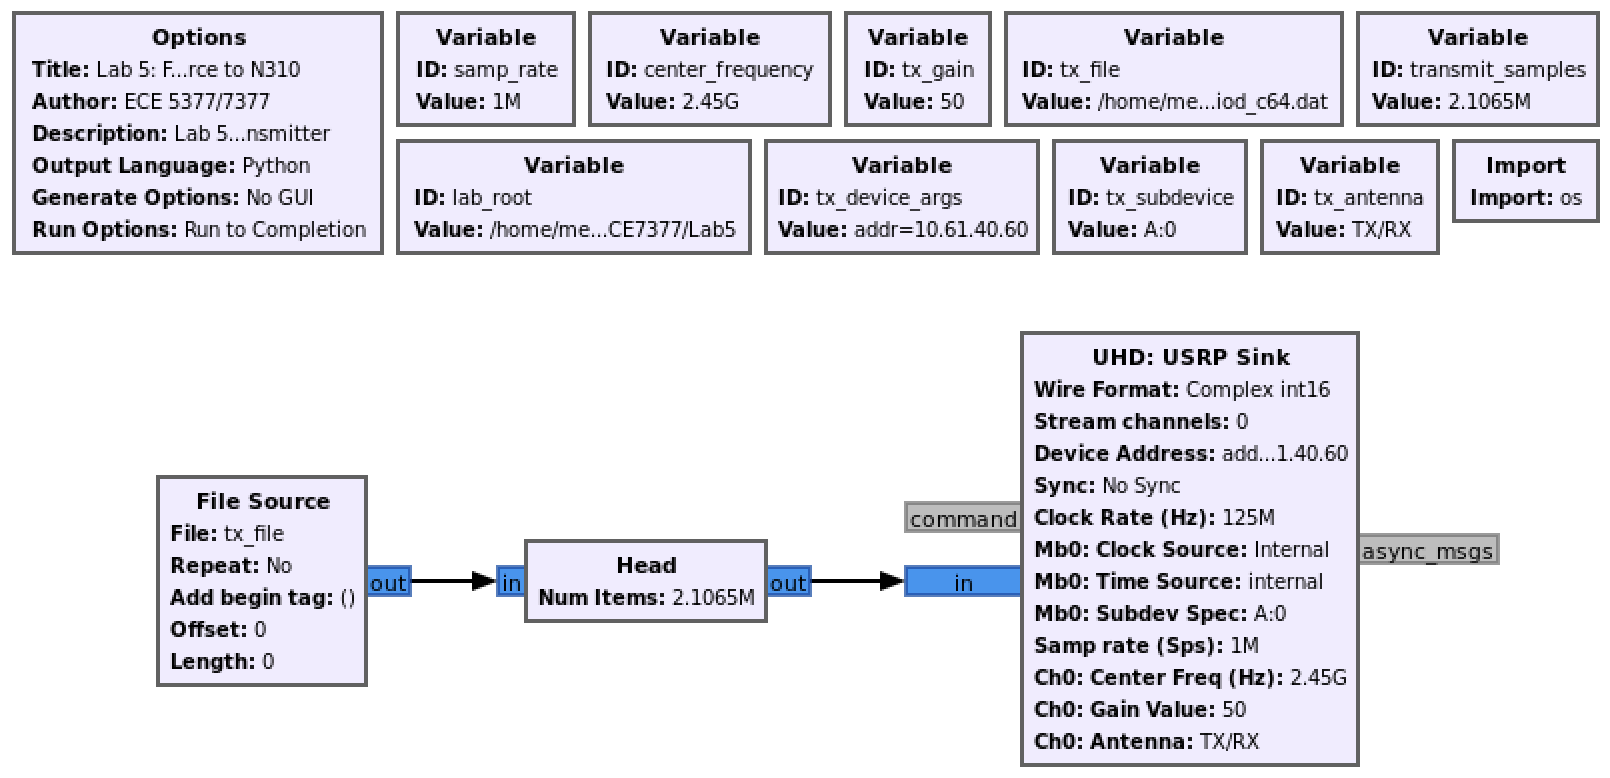

Receiver Flowgraph

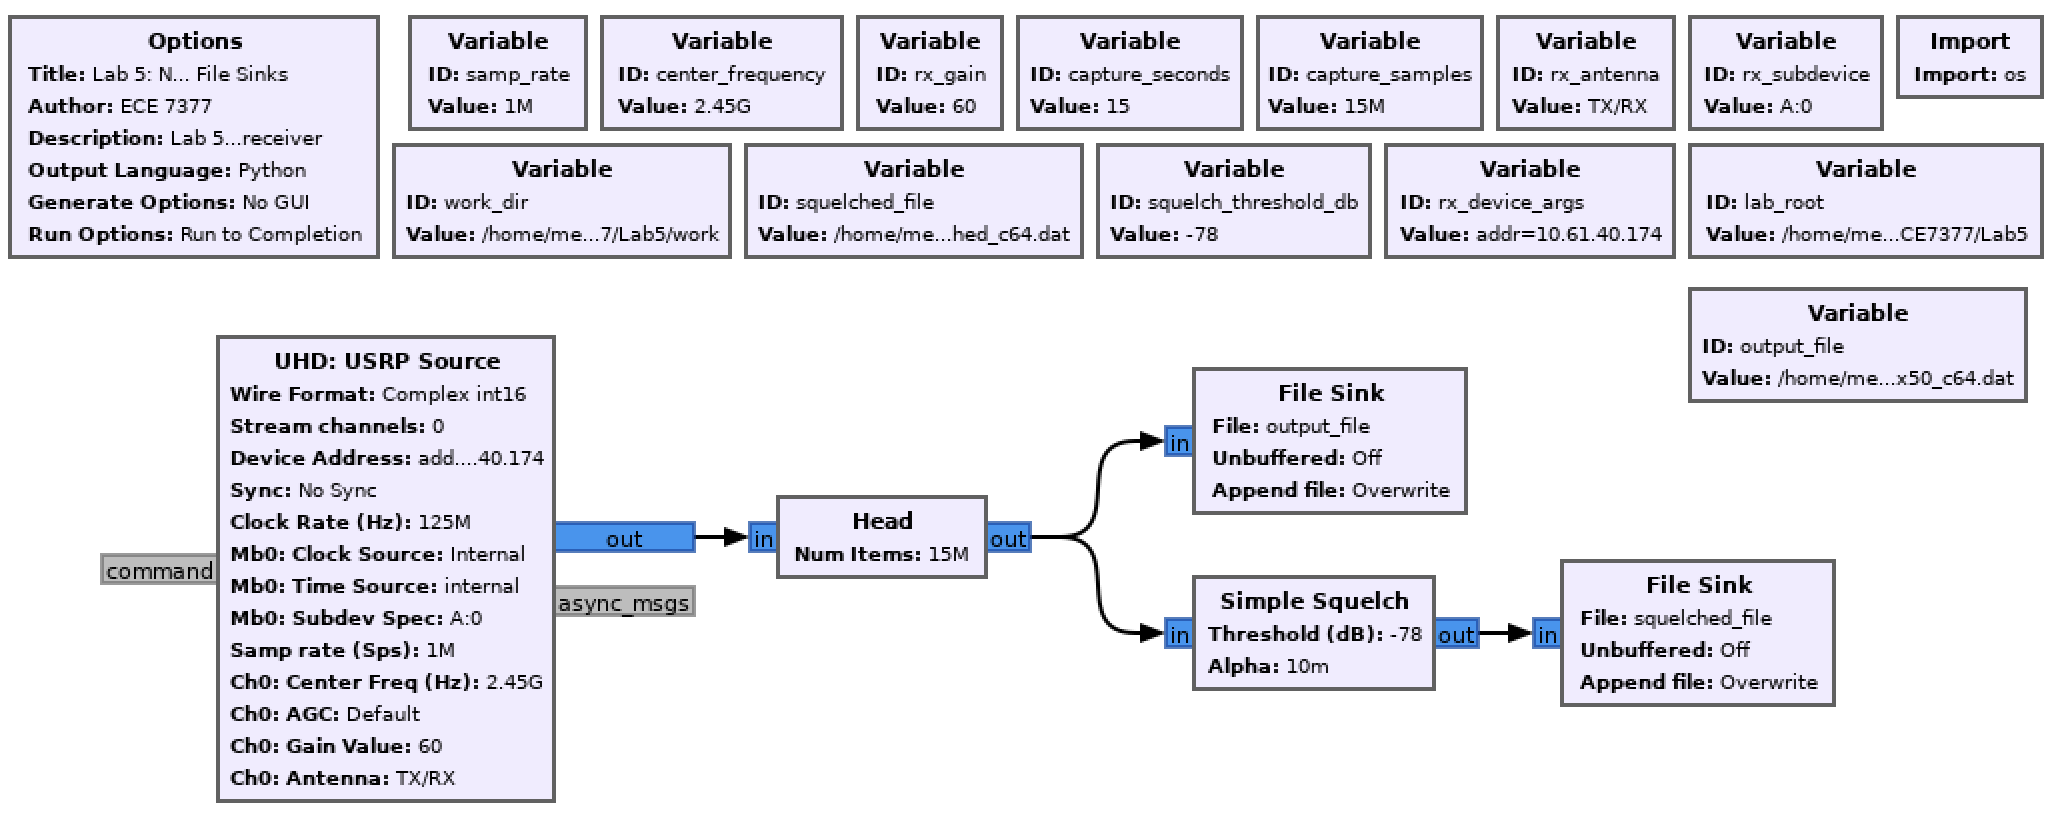

## Analyze the uncropped hardware data


Implemented analyze_channel_estimate as a more concise version of analyze_hardware() only focusing on the channel estimate H

In [15]:
!ls -la $CAPTURE_DIR 

total 390660
drwxr-xr-x 4 mepham mepham     4096 Nov  6 15:14 .
drwxr-xr-x 5 mepham mepham     4096 Nov  3 16:11 ..
drwxr-xr-x 2 mepham mepham     4096 Nov  3 16:11 .ipynb_checkpoints
drwxrwxr-x 2 mepham mepham     4096 Nov  5 02:56 extras
-rw-r--r-- 1 mepham mepham      638 Nov  3 16:14 lab5_measurement_summary.json
-rw-rw-r-- 1 mepham mepham 40000000 Nov  5 02:56 occupancy_p0_r1_c64.dat
-rw-rw-r-- 1 mepham mepham 40000000 Nov  5 02:57 occupancy_p0_r2_c64.dat
-rw-rw-r-- 1 mepham mepham 40000000 Nov  5 02:51 occupancy_p0_r3_c64.dat
-rw-rw-r-- 1 mepham mepham 40000000 Nov  5 02:52 occupancy_p0_r4_c64.dat
-rw-rw-r-- 1 mepham mepham 40000000 Nov  5 02:52 occupancy_p0_r5_c64.dat
-rw-rw-r-- 1 mepham mepham 40000000 Nov  6 15:11 occupancy_p12_r1_c64.dat
-rw-rw-r-- 1 mepham mepham 40000000 Nov  6 15:12 occupancy_p12_r2_c64.dat
-rw-rw-r-- 1 mepham mepham 40000000 Nov  6 15:12 occupancy_p12_r3_c64.dat
-rw-rw-r-- 1 mepham mepham 40000000 Nov  6 15:12 occupancy_p12_r4_c64.dat
-rw-rw-r-- 1 mepham 

Example frame processing showing coarse acquisition using the repeated-preamble metric, fine timing synchronization using cyclic-prefix correlation, FFT demodulation, channel estimation and zero-forcing equalization, pilot-based common phase error correction, and successful packet recovery with CRC pass.

Normalized Complex Correlation: Both magnitude and phase are included in the calculation, so we're all good there.

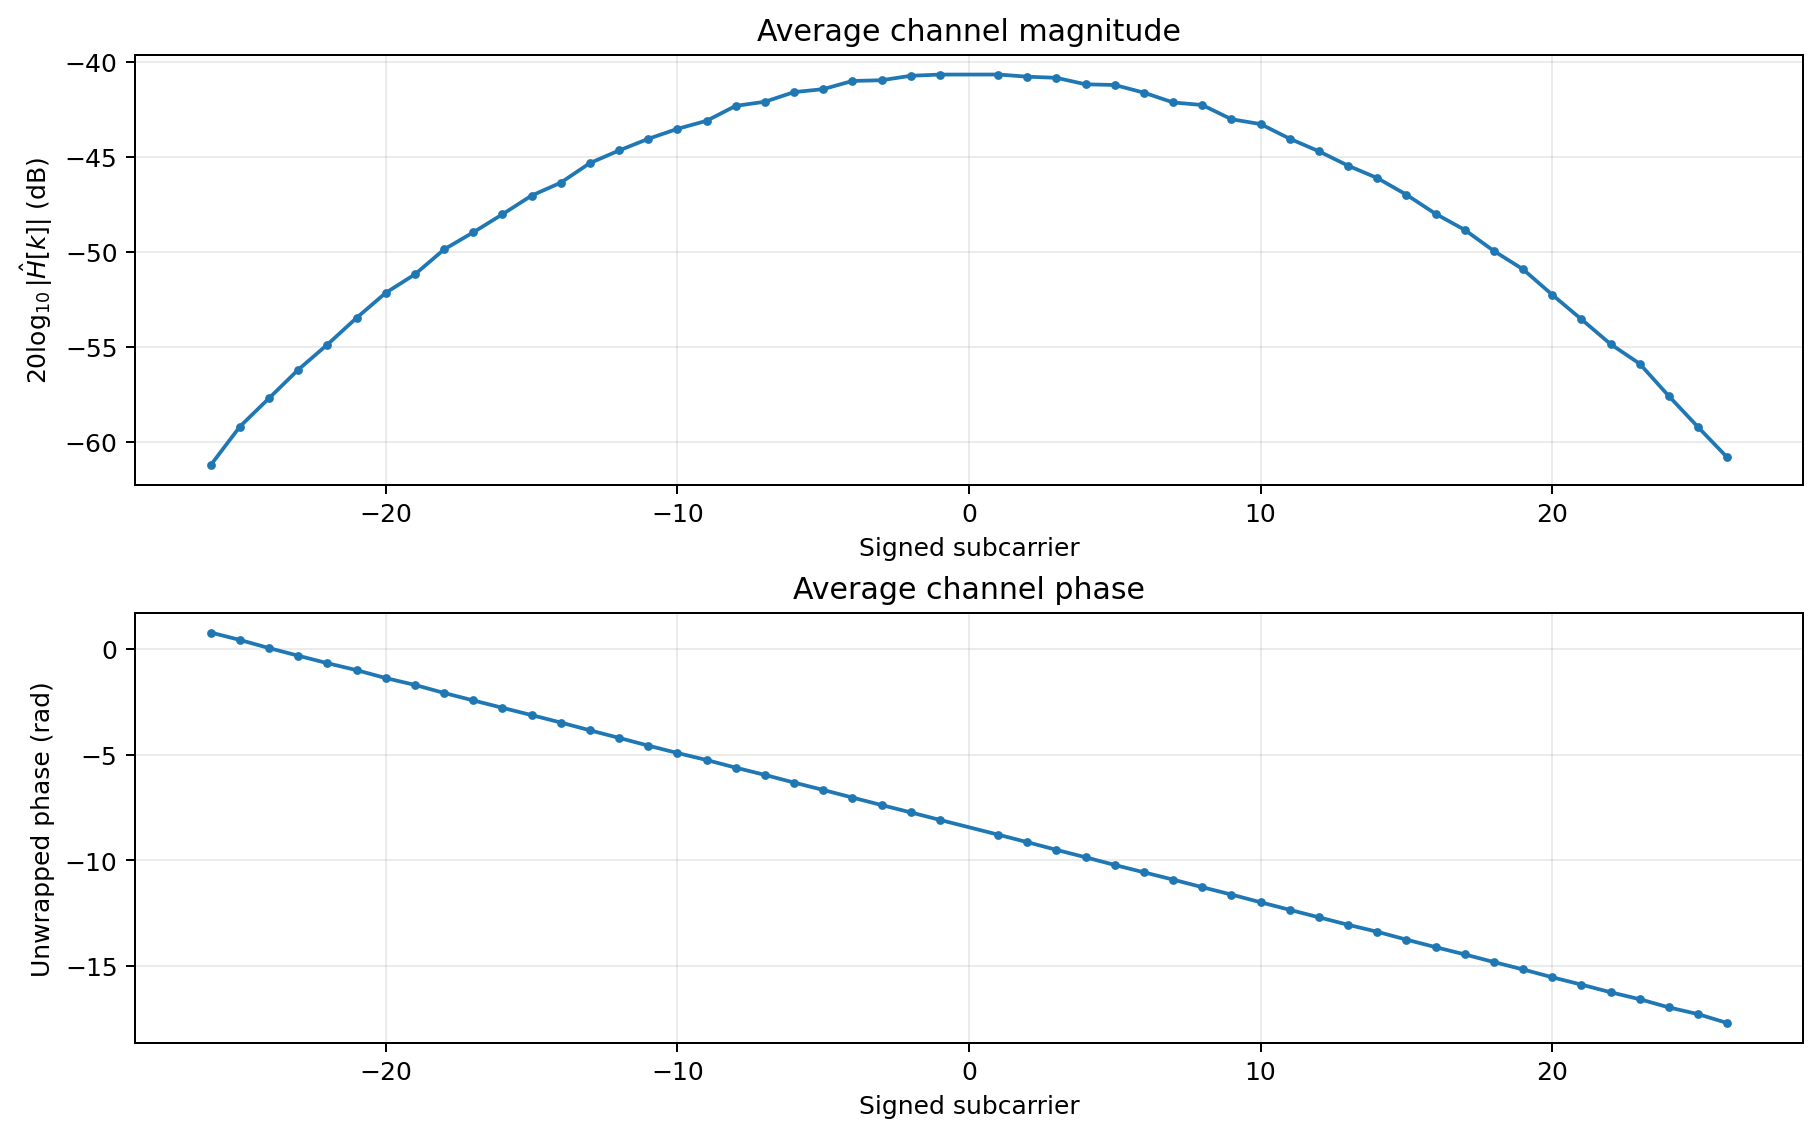

In [10]:
hardware = lab5_tools.analyze_channel_estimate(CAPTURE_DIR, FIGURE_DIR, f"lab5_ofdm_tx50_c64.dat")
path = FIGURE_DIR / f"channel_estimate.png"
display(Image(filename=path))

lab5_tools.channel_correlation(hardware["mean_channel_estimate"], hardware["mean_channel_estimate"])
lab5_tools.channel_nmse(hardware["mean_channel_estimate"], hardware["mean_channel_estimate"])

## Analyze them all at the same time

Names: occupancy_p(Number of People)_r(Run Number)_c64.dat

### PLEASE RUN ONLY THIS ONE FIRST TO SEE IF THERE'S A DIFFERENCE!!

In [16]:
results = lab5_tools.analyze_all_channel_estimates(CAPTURE_DIR)

/home/mepham/ECE7377/OccupancySensing/work/captures/occupancy_p0_r1_c64.dat
/home/mepham/ECE7377/OccupancySensing/work/captures/occupancy_p0_r2_c64.dat
/home/mepham/ECE7377/OccupancySensing/work/captures/occupancy_p0_r3_c64.dat
/home/mepham/ECE7377/OccupancySensing/work/captures/occupancy_p0_r4_c64.dat
/home/mepham/ECE7377/OccupancySensing/work/captures/occupancy_p0_r5_c64.dat
/home/mepham/ECE7377/OccupancySensing/work/captures/occupancy_p12_r1_c64.dat
/home/mepham/ECE7377/OccupancySensing/work/captures/occupancy_p12_r2_c64.dat
/home/mepham/ECE7377/OccupancySensing/work/captures/occupancy_p12_r3_c64.dat
/home/mepham/ECE7377/OccupancySensing/work/captures/occupancy_p12_r4_c64.dat
/home/mepham/ECE7377/OccupancySensing/work/captures/occupancy_p12_r5_c64.dat


In [17]:
lab5_tools.plot_correlation_heatmap(results, FIGURE_DIR)
lab5_tools.plot_channel_magnitude(results, FIGURE_DIR)
lab5_tools.plot_channel_phase(results, FIGURE_DIR)

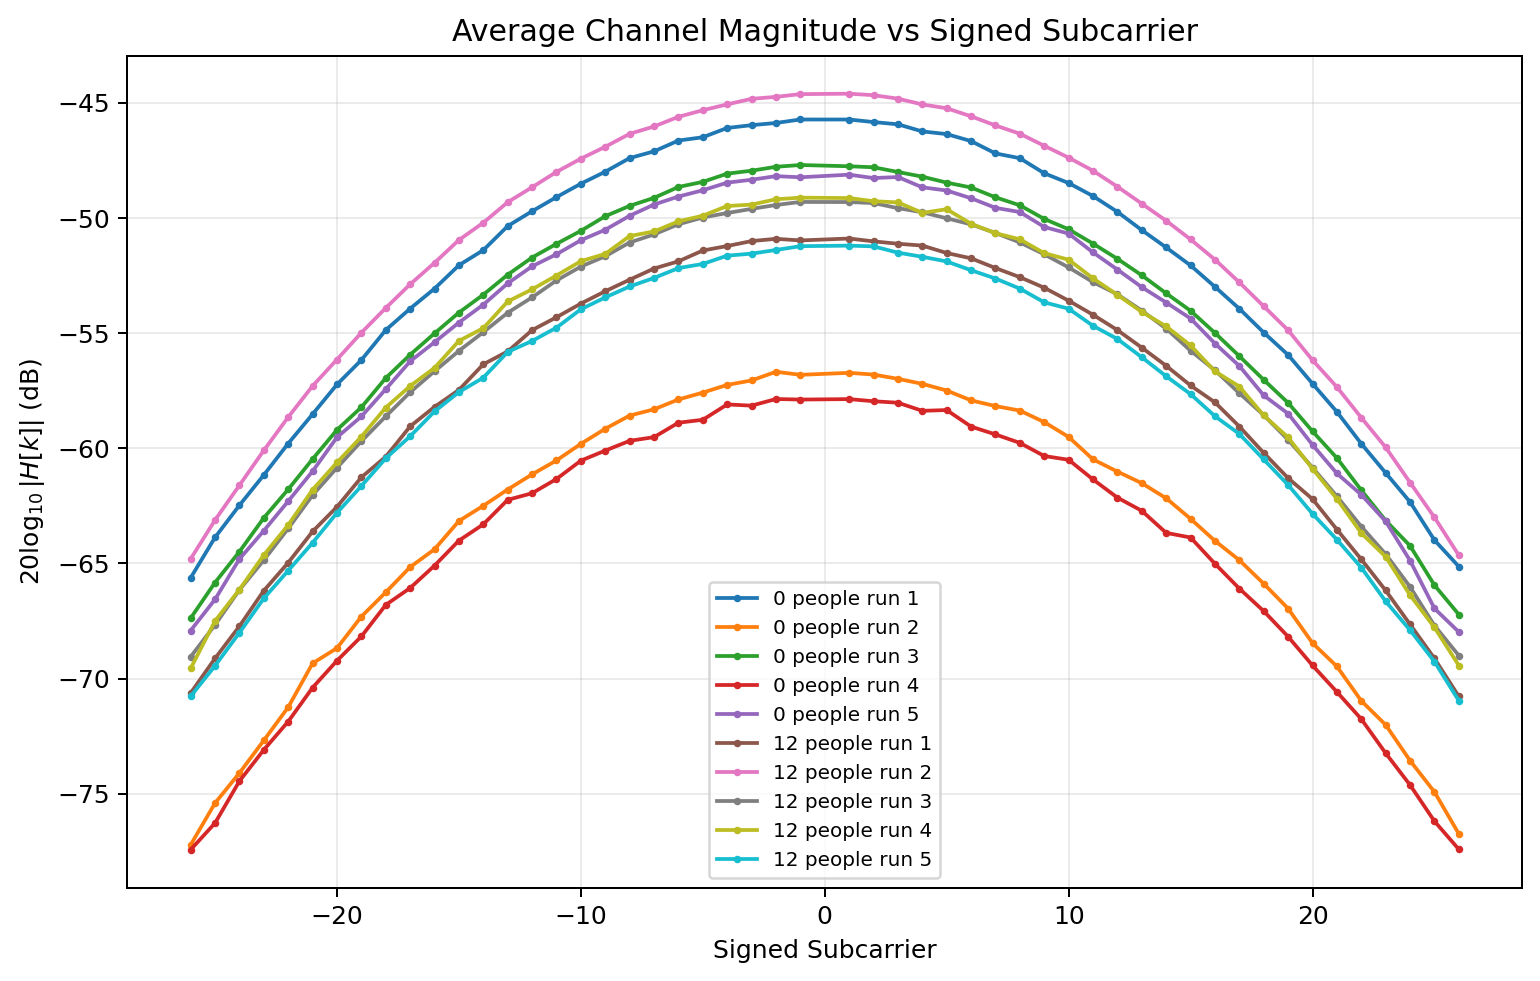

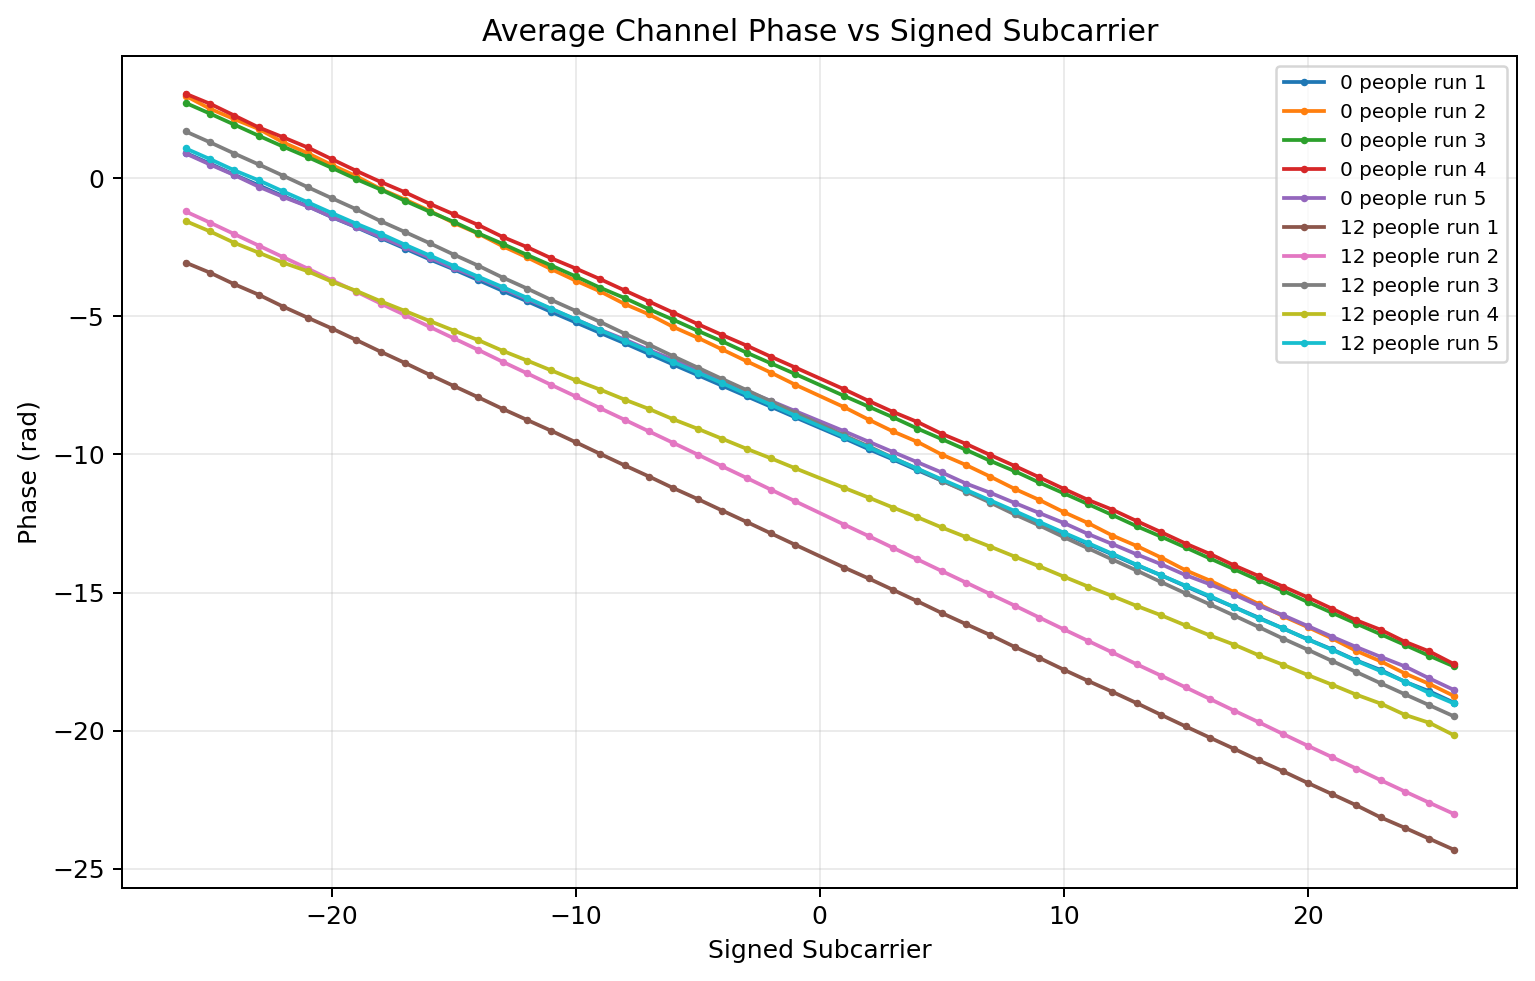

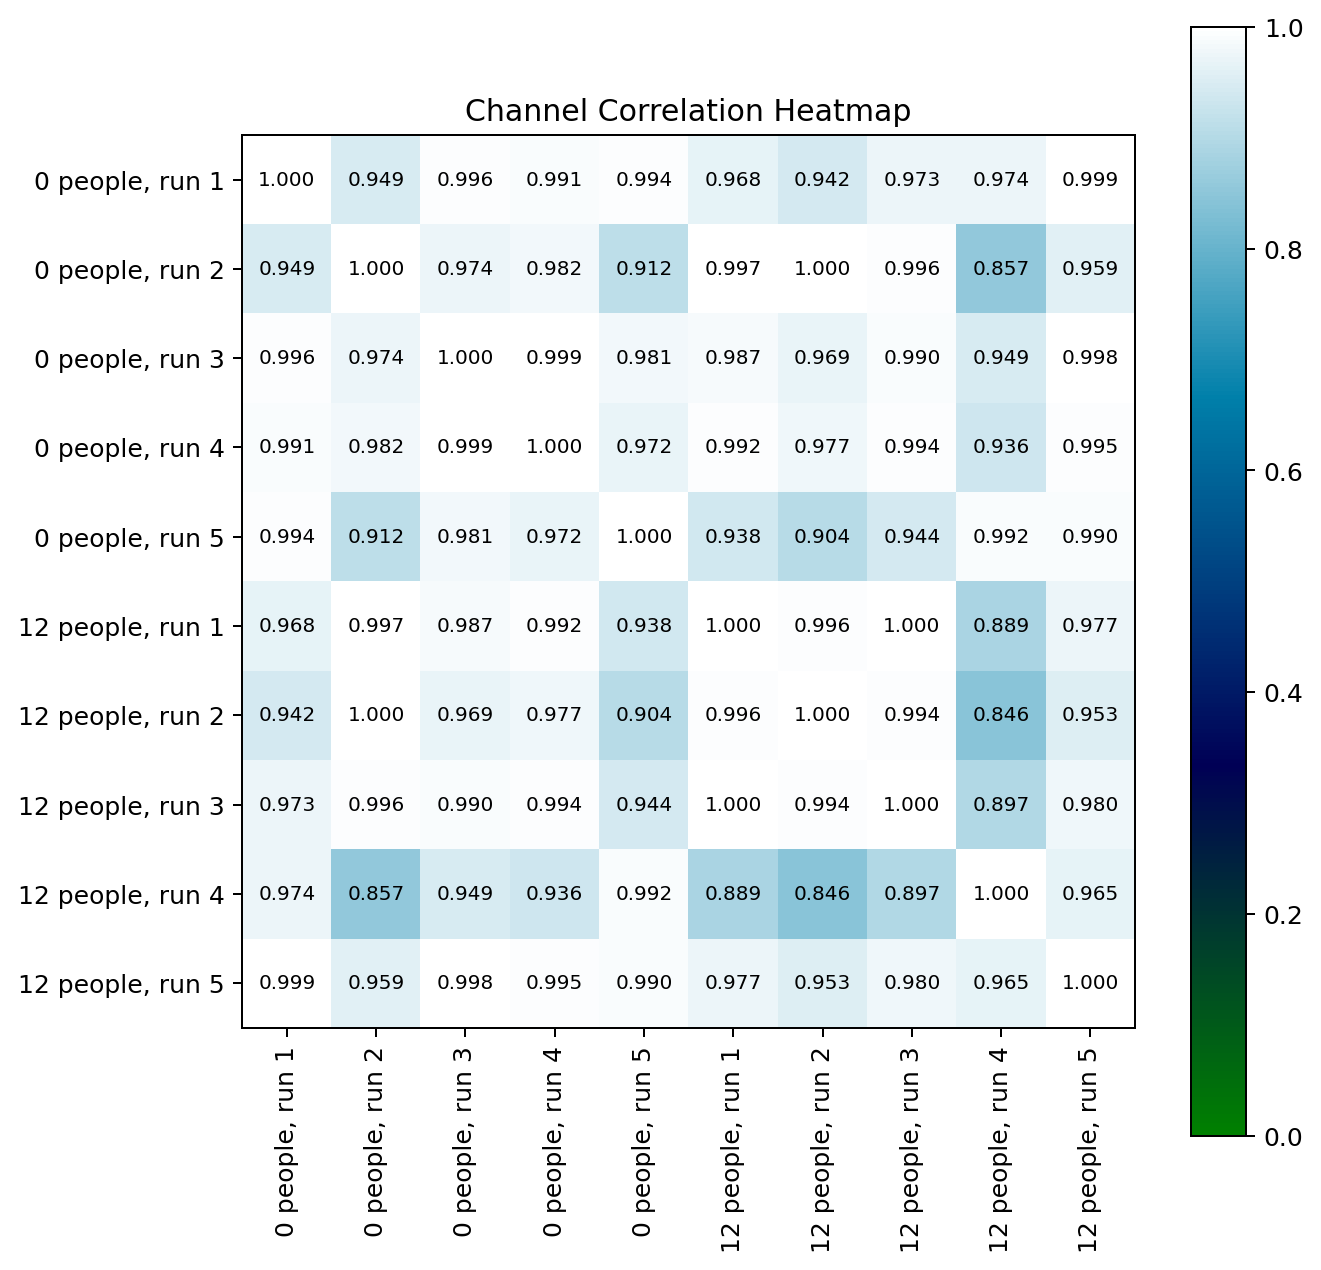

In [18]:
for name in {'occupancy_corr_heatmap', 'occupancy_channel_magnitude', 'occupancy_channel_phase'}:
    path = FIGURE_DIR / f"{name}.png"
    display(Image(filename=path))


In [49]:
plot_nmse(results, FIGURE_DIR)
plot_correlation_heatmap(results, FIGURE_DIR)
plot_mean_correlation(results, FIGURE_DIR)

NameError: name 'plot_channel_magnitude' is not defined

In [6]:
def plot_correlation(results, output_dir):

    H_ref = results[(0,1)]["mean_channel_estimate"]

    fig, ax = plt.subplots(figsize=(8,5))

    for (people, run), result in sorted(results.items()):

        H = result["mean_channel_estimate"]

        corr = channel_corr(H_ref, H)

        ax.scatter(
            people,
            corr,
            s=60,
            label=f"run {run}" if people == 0 else None
        )

    ax.set(
        xlabel="Number of People",
        ylabel="Channel Correlation",
        title="Correlation Relative to Empty-Room Run 1"
    )

    ax.grid(alpha=0.25)

    save_figure(fig, output_dir, "occupancy_correlation")

In [ ]:
def plot_nmse(results, output_dir):

    H_ref = results[(0,1)]["mean_channel_estimate"]

    fig, ax = plt.subplots(figsize=(8,5))

    for (people, run), result in sorted(results.items()):

        H = result["mean_channel_estimate"]

        nmse = channel_nmse(H_ref, H)

        ax.scatter(
            people,
            nmse,
            s=60,
        )

    ax.set(
        xlabel="Number of People",
        ylabel="NMSE",
        title="NMSE Relative to Empty-Room Run 1"
    )

    ax.grid(alpha=0.25)

    save_figure(fig, output_dir, "occupancy_nmse")

In [ ]:
def plot_mean_correlation(results, output_dir):

    H_ref = results[(0,1)]["mean_channel_estimate"]

    occupancy = sorted(
        set(p for p, r in results.keys())
    )

    means = []
    stds = []

    for p in occupancy:

        vals = []

        for run in [1,2,3]:

            if (p,run) not in results:
                continue

            H = results[(p,run)]["mean_channel_estimate"]

            vals.append(
                channel_corr(H_ref, H)
            )

        means.append(np.mean(vals))
        stds.append(np.std(vals))

    fig, ax = plt.subplots(figsize=(8,5))

    ax.errorbar(
        occupancy,
        means,
        yerr=stds,
        fmt='o-',
        capsize=5
    )

    ax.set(
        xlabel="Number of People",
        ylabel="Mean Correlation",
        title="Occupancy Impact on Channel Correlation"
    )

    ax.grid(alpha=0.25)

    save_figure(fig, output_dir, "occupancy_mean_correlation")